# Experiment 04 — Multi-Period Stress-Regime Validation and Statistical Model Comparison

**Researcher:** Ezekiel Apima Onchong’a  
**Research portfolio:** [regime-aware-option-pricing](https://github.com/apimaezekiel-arch/regime-aware-option-pricing)  
**Companion:** `03_volatility_asymmetry_and_regime_detection.ipynb`

## Research question
Do GJR-GARCH(1,1) and EGARCH(1,1) improve **one-day-ahead** variance forecasts relative to symmetric GARCH(1,1), and are any advantages stable across crisis, bear-market, calmer, and recent market episodes?

**Connection to Experiment 03:** Same SPY underlying, daily log returns in percent, normal innovations, 750-observation rolling estimation window, ten-day parameter refits, and QLIKE / variance-MSE evaluation. Experiment 03 tested only the last 120 days of 2025; this experiment adds four non-overlapping historical windows. Results must be re-estimated; prior findings are not assumed.

**Scope:** This tests volatility *forecasts*, not option prices or trading profitability. Outputs are not claimed until you execute the notebook.

## 1. Installation and reproducibility
In Colab choose **Runtime → Run all**. Package installation and SPY download require internet. Download the exported files before the Colab runtime is reset.

In [12]:
%pip -q install "yfinance>=0.2.50" "arch>=7.0" "numpy>=1.24" "pandas>=2.0" "scipy>=1.10" "matplotlib>=3.7"

In [13]:
from pathlib import Path
import sys, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from scipy.stats import norm
from arch import arch_model
import arch, yfinance as yf
from IPython.display import display

SEED = 20261017
RNG = np.random.default_rng(SEED)
OUTPUT = Path('results_exp04'); OUTPUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize': (11, 4.5), 'axes.grid': True})
print({'python':sys.version.split()[0], 'numpy':np.__version__, 'pandas':pd.__version__,
       'arch':arch.__version__, 'scipy':scipy.__version__, 'yfinance':yf.__version__})

{'python': '3.13.16', 'numpy': '2.1.3', 'pandas': '2.2.3', 'arch': '8.0.0', 'scipy': '1.16.3', 'yfinance': '0.2.66'}


## 2. Data, windows, and leakage prevention
We extend the history to **2017** so the 2020 COVID crisis has a full preceding estimation window. The four named periods are chosen **before** comparing model performance, and are *historical event labels*, not ex-ante market-regime predictions. An independent **ex-ante volatility bucket** is also constructed from lagged 21-day realized standard deviation and its prior 504-day distribution.

Daily returns are `100 × log(adjusted close_t / adjusted close_(t−1))`; conditional variance and squared returns are in **squared percentage points**. Yahoo adjusted prices are subject to vendor revisions. The data sample stops at 2025-12-31, for consistency with Experiment 03.

In [14]:
TICKER='SPY'
START='2017-01-01'; END='2026-01-01' # end-exclusive
ESTIMATION_WINDOW=750
REFIT_EVERY=10
MAX_DAYS_PER_PERIOD=90   # keeps Google Colab run time manageable; set None for all days
PERIODS={
    'COVID shock 2020':('2020-02-20','2020-06-30'),
    'Bear market 2022':('2022-04-01','2022-08-31'),
    'Calmer 2023':('2023-06-01','2023-10-31'),
    'Recent 2025':('2025-07-01','2025-12-31'),
}
raw=yf.download(TICKER,start=START,end=END,auto_adjust=True,progress=False)
if raw.empty: raise RuntimeError('Download returned no observations; check network or data provider.')
close=raw['Close']
if isinstance(close,pd.DataFrame): close=close[TICKER] if TICKER in close.columns else close.iloc[:,0]
close=pd.to_numeric(close,errors='coerce').dropna().sort_index()
close=close.loc[~close.index.duplicated(keep='last')]
returns=(100*np.log(close/close.shift(1))).dropna()
assert returns.index.is_monotonic_increasing and len(returns)>ESTIMATION_WINDOW
assert np.isfinite(returns).all()
print('SPY returns:',len(returns),'from',returns.index.min().date(),'to',returns.index.max().date())

windows={}
for label,(lo,hi) in PERIODS.items():
    dates=returns.loc[lo:hi].index
    if MAX_DAYS_PER_PERIOD is not None: dates=dates[:MAX_DAYS_PER_PERIOD]
    if not len(dates): raise ValueError('No data for '+label)
    if returns.index.get_loc(dates[0])<ESTIMATION_WINDOW: raise ValueError('Insufficient pre-test history for '+label)
    windows[label]=dates
    print(f'{label}: {len(dates)} forecast days, {dates[0].date()} to {dates[-1].date()}')
all_dates=pd.DatetimeIndex(np.concatenate([np.asarray(x) for x in windows.values()]))
assert all_dates.is_unique, 'Periods must not overlap'
assert all_dates.is_monotonic_increasing, 'Windows must be ordered chronologically'

# At forecast date t, this signal uses observations through t-1.
lagged_rv21=returns.rolling(21).std().shift(1)
# Thresholds computed from a strictly earlier 504-day history of lagged RV observations.
low_cut=lagged_rv21.shift(1).rolling(504,min_periods=252).quantile(1/3)
high_cut=lagged_rv21.shift(1).rolling(504,min_periods=252).quantile(2/3)
def ex_ante_bucket(day):
    z,a,b=lagged_rv21.loc[day],low_cut.loc[day],high_cut.loc[day]
    if not np.isfinite([z,a,b]).all(): return 'Unclassified'
    return 'Low' if z<a else ('High' if z>b else 'Medium')

SPY returns: 2261 from 2017-01-04 to 2025-12-31
COVID shock 2020: 90 forecast days, 2020-02-20 to 2020-06-26
Bear market 2022: 90 forecast days, 2022-04-01 to 2022-08-10
Calmer 2023: 90 forecast days, 2023-06-01 to 2023-10-09
Recent 2025: 90 forecast days, 2025-07-01 to 2025-11-05


## 3. Forecast design
At the start of each 10-day block, fit each model on only the **750 most recent returns before the forecast date**. Each subsequent day, keep those parameter estimates fixed but update the filtering history through the prior close (`arch_model.fix`); forecast variance for the *next* day from that filtered state. This is a realistic periodic-recalibration design and never refits using the target day's return.

Fit parameters with the same Student's choice of **normal innovations** used in Experiment 03; sensitivity to Student-t innovations can be studied later. A failed fit produces a flagged missing forecast rather than a secretly substituted model. Persist every failure for inspection.

In [15]:
MODELS={
    'GARCH':dict(vol='GARCH',p=1,o=0,q=1),
    'GJR-GARCH':dict(vol='GARCH',p=1,o=1,q=1),
    'EGARCH':dict(vol='EGARCH',p=1,o=1,q=1),
}
def make_model(series,name):
    return arch_model(series,mean='Zero',dist='normal',rescale=False,**MODELS[name])

predictions=[]; fits=[]; failures=[]
for label,dates in windows.items():
    print('Working on:',label)
    for start in range(0,len(dates),REFIT_EVERY):
        block=dates[start:start+REFIT_EVERY]
        first_loc=returns.index.get_loc(block[0])
        training=returns.iloc[first_loc-ESTIMATION_WINDOW:first_loc]
        fit_results={}
        for name in MODELS:
            try:
                fitted=make_model(training,name).fit(disp='off',show_warning=False)
                if fitted.convergence_flag!=0:
                    raise RuntimeError(f'Optimizer convergence flag={fitted.convergence_flag}')
                params=fitted.params.copy()
                fit_results[name]=params
                fits.append({'period':label,'fit_at':block[0], 'model':name,'loglikelihood':fitted.loglikelihood,
                             'convergence':int(fitted.convergence_flag), **{k:float(v) for k,v in params.items()}})
            except Exception as exc:
                fit_results[name]=None
                failures.append({'period':label,'date':block[0],'model':name,'stage':'fit','error':str(exc)})
        for day in block:
            i=returns.index.get_loc(day)
            prior=returns.iloc[i-ESTIMATION_WINDOW:i]
            row={'date':day,'period':label,'realized_return_pct':float(returns.loc[day]),
                 'proxy_variance':float(returns.loc[day]**2),
                 'lagged_rv21':float(lagged_rv21.loc[day]), 'ex_ante_regime':ex_ante_bucket(day)}
            for name,params in fit_results.items():
                value=np.nan
                if params is not None:
                    try:
                        fixed=make_model(prior,name).fix(params)
                        value=float(fixed.forecast(horizon=1,reindex=False).variance.iloc[-1,0])
                        if not np.isfinite(value) or value<=0: raise ValueError('Nonpositive/nonfinite forecast')
                    except Exception as exc:
                        failures.append({'period':label,'date':day,'model':name,'stage':'forecast','error':str(exc)})
                row[name]=value
            predictions.append(row)
pred=pd.DataFrame(predictions).set_index('date').sort_index()
fit_table=pd.DataFrame(fits); fail_table=pd.DataFrame(failures)
print('Forecast dates:',len(pred),'Failed fit/forecast events:',len(fail_table))
if not fail_table.empty: display(fail_table.head(15))
display(pred.head())

Working on: COVID shock 2020
Working on: Bear market 2022
Working on: Calmer 2023
Working on: Recent 2025
Forecast dates: 360 Failed fit/forecast events: 0


,period,realized_return_pct,proxy_variance,lagged_rv21,ex_ante_regime,GARCH,GJR-GARCH,EGARCH
date,,,,,,,,
2020-02-20,COVID shock 2020,-0.411679,0.169480,0.828357,Medium,0.349323,0.282193,0.317628
2020-02-21,COVID shock 2020,-1.035150,1.071536,0.833412,Medium,0.333051,0.317505,0.395607
2020-02-24,COVID shock 2020,-3.372783,11.375665,0.868312,Medium,0.500147,0.685554,0.746153
2020-02-25,COVID shock 2020,-3.077111,9.468613,1.141853,High,2.674745,4.862406,3.891613
2020-02-26,COVID shock 2020,-0.368471,0.135771,1.302474,High,3.933543,7.376799,5.943421


## 4. Integrity checks and comparison sample
The **common comparison sample** only includes dates with valid forecasts from all three models. Always report dropped dates. A large number of failures can invalidate inference; do not silently ignore them. The squared daily return is a noisy proxy for latent variance, so no claim of observing true conditional variance is made.

In [16]:
common=pred.dropna(subset=list(MODELS)+['proxy_variance']).copy()
coverage=pd.DataFrame({'available_forecasts':pred.groupby('period')[list(MODELS)].count().min(axis=1),
                       'common_dates':common.groupby('period').size()}).fillna(0).astype(int)
coverage['requested_dates']=pred.groupby('period').size()
coverage['dropped_dates']=coverage['requested_dates']-coverage['common_dates']
display(coverage)
if common.empty: raise RuntimeError('No common dates; inspect failed fits and internet/data setup.')
if (coverage.common_dates<30).any(): warnings.warn('One or more periods have fewer than 30 matched forecasts; tests may be unstable.')
assert (common[list(MODELS)]>0).all().all()
assert common.index.is_unique

def qlike(observed,variance): return np.log(variance)+observed/variance
for name in MODELS:
    common[f'{name}_MSE_loss']=(common['proxy_variance']-common[name])**2
    common[f'{name}_QLIKE_loss']=qlike(common['proxy_variance'],common[name])

def score_rows(df,dimension,group):
    rows=[]
    for name in MODELS:
        rows.append({dimension:group,'model':name,'n':len(df),
                     'MSE':df[f'{name}_MSE_loss'].mean(),
                     'QLIKE':df[f'{name}_QLIKE_loss'].mean()})
    return rows
scores=pd.DataFrame(score_rows(common,'period','Pooled')+
  [row for label,g in common.groupby('period',sort=False) for row in score_rows(g,'period',label)])
display(scores.round(5))

,available_forecasts,common_dates,requested_dates,dropped_dates
period,,,,
Bear market 2022,90,90,90,0
COVID shock 2020,90,90,90,0
Calmer 2023,90,90,90,0
Recent 2025,90,90,90,0


,period,model,n,MSE,QLIKE
0,Pooled,GARCH,360,95.42815,1.473160e+00
1,Pooled,GJR-GARCH,360,110.15631,1.545120e+00
2,Pooled,EGARCH,360,inf,1.793356e+37
3,COVID shock 2020,GARCH,90,364.78999,3.312160e+00
4,COVID shock 2020,GJR-GARCH,90,420.77303,3.670920e+00
5,COVID shock 2020,EGARCH,90,384.36798,3.635150e+00
6,Bear market 2022,GARCH,90,15.59537,2.008140e+00
7,Bear market 2022,GJR-GARCH,90,18.53140,2.008070e+00
8,Bear market 2022,EGARCH,90,16.68016,1.983960e+00
9,Calmer 2023,GARCH,90,0.41567,3.268500e-01


## 5. Forecast charts by historical episode
Forecast daily *standard deviation* is the square root of the variance forecast, and the absolute observed return is only a noisy visualization proxy. Charts are not proof of forecasting superiority.

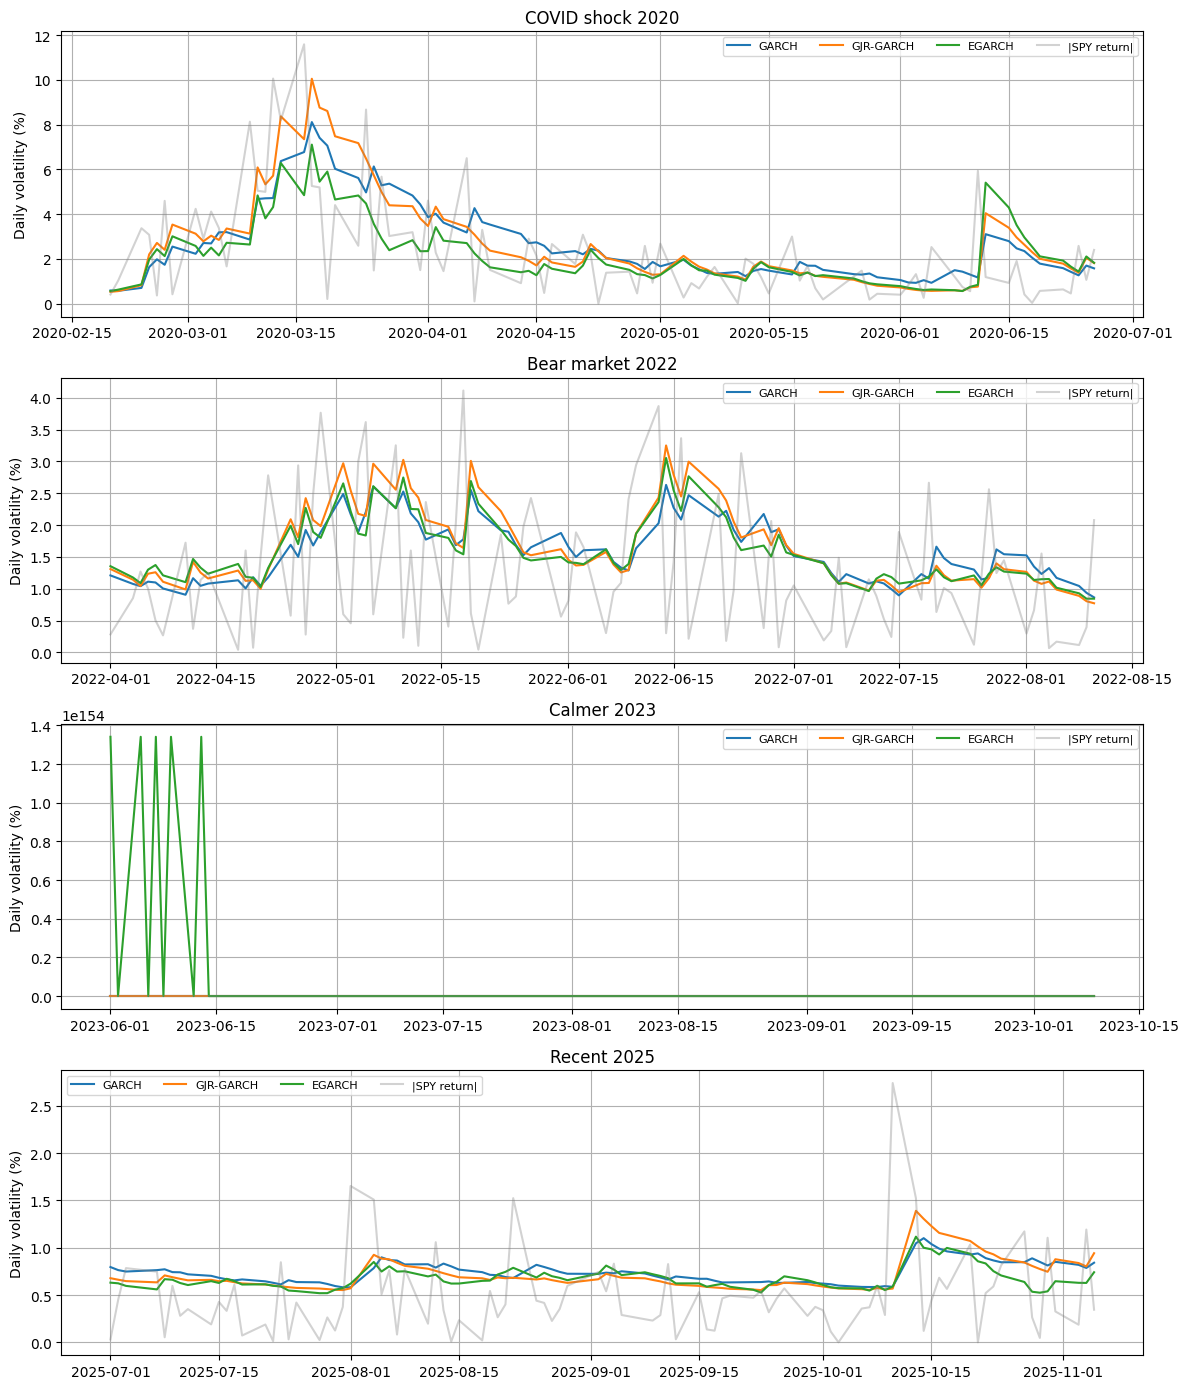

In [17]:
fig,axes=plt.subplots(len(windows),1,figsize=(12,3.5*len(windows)),sharex=False)
for ax,(label,g) in zip(np.atleast_1d(axes),common.groupby('period',sort=False)):
    for name in MODELS: ax.plot(g.index,np.sqrt(g[name]),label=name,lw=1.5)
    ax.plot(g.index,g.realized_return_pct.abs(),color='gray',alpha=.35,label='|SPY return|')
    ax.set(title=label,ylabel='Daily volatility (%)')
    ax.legend(ncol=4,fontsize=8)
plt.tight_layout();fig.savefig(OUTPUT/'volatility_by_period.png',dpi=160)
plt.show()

## 6. Ex-ante volatility regimes
Each forecast date is assigned to a low/medium/high volatility bucket based only on lagged realized volatility and earlier rolling quantiles. This is different from labeling an episode *in hindsight*. Report counts: an empty or tiny bucket cannot support conclusions.

In [18]:
regime_counts=common.ex_ante_regime.value_counts().rename_axis('regime').to_frame('n')
display(regime_counts)
regime_scores=pd.DataFrame([row for label,g in common.groupby('ex_ante_regime')
                            for row in score_rows(g,'regime',label)])
display(regime_scores.sort_values(['regime','QLIKE']).round(5))

,n
regime,
High,169
Low,156
Medium,35


,regime,model,n,MSE,QLIKE
0,High,GARCH,169,201.08138,2.488730e+00
2,High,EGARCH,169,212.19332,2.693270e+00
1,High,GJR-GARCH,169,232.57392,2.718480e+00
4,Low,GJR-GARCH,156,0.68349,2.358700e-01
3,Low,GARCH,156,0.70084,2.770400e-01
5,Low,EGARCH,156,inf,4.138513e+37
8,Medium,EGARCH,35,6.90677,1.647960e+00
7,Medium,GJR-GARCH,35,6.99008,1.714960e+00
6,Medium,GARCH,35,7.48710,1.900690e+00


## 7. Paired forecast-comparison inference
Loss differential is `loss(A) − loss(B)`, so positive values favor B. We use two complementary diagnostics:

1. **HAC / Diebold–Mariano-style z test** of mean daily loss differential within each **contiguous episode**, using a Newey–West long-run variance with lag 5. This is an *approximate*, not an exact, small-sample DM test.
2. **Period-stratified moving-block bootstrap** for pooled mean differences: sample consecutive 5-day blocks *within* each episode, preserving each period's contribution, rather than connecting noncontiguous episodes. Report percentile confidence intervals and approximate two-sided tail probabilities; they are not exact null-centered bootstrap p-values.

For six prespecified pairwise QLIKE/MSE comparisons, apply **Holm family-wise correction** to episode-specific HAC p-values *within each episode/metric family*. Inference remains exploratory because multiple design choices and events were inspected. Important: the squared-return proxy is noisy, and differences may be sensitive to covariance estimates and the bootstrap block size.

In [19]:
from itertools import combinations
PAIRWISE=list(combinations(MODELS,2))

def hac_mean_test(d,lag=5):
    x=np.asarray(d,dtype=float); x=x[np.isfinite(x)]; n=len(x)
    if n<max(15,lag+3): return (np.nan,np.nan,np.nan)
    centered=x-x.mean()
    v=float(np.dot(centered,centered)/n)
    for k in range(1,min(lag,n-1)+1):
        gamma=float(np.dot(centered[k:],centered[:-k])/n)
        v+=2*(1-k/(lag+1))*gamma
    if not np.isfinite(v) or v<=0: return (float(x.mean()),np.nan,np.nan)
    se=np.sqrt(v/n); z=float(x.mean()/se)
    return float(x.mean()), float(se), float(2*norm.sf(abs(z)))

def holm_adjust(pvals):
    p=np.asarray(pvals,dtype=float); out=np.full(len(p),np.nan)
    idx=np.where(np.isfinite(p))[0]
    ordered=idx[np.argsort(p[idx])]; m=len(ordered); running=0.0
    for rank,i in enumerate(ordered):
        running=max(running,min(1.0,(m-rank)*p[i]))
        out[i]=running
    return out

stat_rows=[]
for label,g in common.groupby('period',sort=False):
    for metric in ['QLIKE','MSE']:
        for a,b in PAIRWISE:
            d=g[f'{a}_{metric}_loss']-g[f'{b}_{metric}_loss']
            mean,se,p=hac_mean_test(d,lag=5)
            stat_rows.append({'period':label,'metric':metric,'A':a,'B':b,
                              'n':len(d),'mean_loss_A_minus_B':mean,'HAC_SE':se,'p_raw':p})
hac_table=pd.DataFrame(stat_rows)
hac_table['p_holm']=np.nan
for (_, _), idx in hac_table.groupby(['period','metric']).groups.items():
    hac_table.loc[list(idx),'p_holm']=holm_adjust(hac_table.loc[list(idx),'p_raw'])
display(hac_table.round(5))

,period,metric,A,B,n,mean_loss_A_minus_B,HAC_SE,p_raw,p_holm
0,COVID shock 2020,QLIKE,GARCH,GJR-GARCH,90,-3.587600e-01,4.386100e-01,0.41339,0.94229
1,COVID shock 2020,QLIKE,GARCH,EGARCH,90,-3.229900e-01,3.208500e-01,0.31410,0.94229
2,COVID shock 2020,QLIKE,GJR-GARCH,EGARCH,90,3.577000e-02,1.421800e-01,0.80134,0.94229
3,COVID shock 2020,MSE,GARCH,GJR-GARCH,90,-5.598304e+01,8.304738e+01,0.50024,1.00000
4,COVID shock 2020,MSE,GARCH,EGARCH,90,-1.957799e+01,4.607416e+01,0.67089,1.00000
5,COVID shock 2020,MSE,GJR-GARCH,EGARCH,90,3.640505e+01,1.028395e+02,0.72334,1.00000
6,Bear market 2022,QLIKE,GARCH,GJR-GARCH,90,6.000000e-05,2.936000e-02,0.99824,1.00000
7,Bear market 2022,QLIKE,GARCH,EGARCH,90,2.418000e-02,3.624000e-02,0.50466,1.00000
8,Bear market 2022,QLIKE,GJR-GARCH,EGARCH,90,2.411000e-02,2.039000e-02,0.23706,0.71118
9,Bear market 2022,MSE,GARCH,GJR-GARCH,90,-2.936030e+00,1.348960e+00,0.02952,0.05903


In [20]:
def block_resample_mean(parts,block=5,reps=2000,seed=SEED):
    rng=np.random.default_rng(seed)
    observed=np.concatenate(parts).mean(); samples=np.empty(reps)
    for b in range(reps):
        drawn=[]
        for x in parts:
            n=len(x); k=min(block,n); starts=rng.integers(0,n-k+1,size=int(np.ceil(n/k)))
            drawn.append(np.concatenate([x[s:s+k] for s in starts])[:n])
        samples[b]=np.concatenate(drawn).mean()
    low,high=np.quantile(samples,[.025,.975])
    # Bootstrap sign-tail diagnostic; interpret cautiously, not as an exact null test.
    sign_tail=2*min((1+np.count_nonzero(samples<=0))/(reps+1),
                    (1+np.count_nonzero(samples>=0))/(reps+1))
    return float(observed),float(low),float(high),float(min(1.,sign_tail))

boot_rows=[]
for metric in ['QLIKE','MSE']:
    for pair_index,(a,b) in enumerate(PAIRWISE):
        parts=[(g[f'{a}_{metric}_loss']-g[f'{b}_{metric}_loss']).to_numpy()
               for _,g in common.groupby('period',sort=False)]
        mean,low,high,p=block_resample_mean(parts,block=5,reps=2000,seed=SEED+pair_index)
        boot_rows.append({'metric':metric,'A':a,'B':b,'n':sum(map(len,parts)),
                          'mean_loss_A_minus_B':mean,'CI_2.5pct':low,'CI_97.5pct':high,
                          'bootstrap_sign_tail_diagnostic':p})
bootstrap_results=pd.DataFrame(boot_rows)
display(bootstrap_results.round(5))

/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:4620: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:4620: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)


,metric,A,B,n,mean_loss_A_minus_B,CI_2.5pct,CI_97.5pct,bootstrap_sign_tail_diagnostic
0,QLIKE,GARCH,GJR-GARCH,360,-7.196000e-02,-3.154300e-01,0.07875,0.56072
1,QLIKE,GARCH,EGARCH,360,-1.793356e+37,-3.288203e+37,0.00293,0.05797
2,QLIKE,GJR-GARCH,EGARCH,360,-1.793356e+37,-3.419066e+37,0.04536,0.15792
3,MSE,GARCH,GJR-GARCH,360,-1.472816e+01,-6.916431e+01,17.04345,0.58371
4,MSE,GARCH,EGARCH,360,-inf,NaN,5.58517,0.09995
5,MSE,GJR-GARCH,EGARCH,360,-inf,NaN,39.24257,0.17391


## 8. Robustness and limitations
- **Lag sensitivity:** repeat HAC diagnostics for lags 1, 5, and 10; inference should not rest on a single selected lag.
- **Regime counts:** verify observations per regime and episode. Four targeted windows are not the entire time series.
- **Calibration convergence:** examine `failed_events.csv`, optimizer flags, and raw fit parameters before interpreting any ranking.
- **Model risk:** normal innovations, fixed refit cadence, daily squared returns as noisy variance proxy, and volatility proxy-based regimes are methodological choices. A future extension should test Student-t innovations, alternative refit rates, realized variance from intraday data, and option-level pricing.
- **Multiple comparisons:** statistical significance here does not automatically establish economic or trading value.

,period,HAC_lag,A,B,mean_QLIKE_diff,p_raw
0,COVID shock 2020,1,GARCH,GJR-GARCH,-3.588000e-01,0.3679
1,COVID shock 2020,1,GARCH,EGARCH,-3.230000e-01,0.2627
2,COVID shock 2020,1,GJR-GARCH,EGARCH,3.580000e-02,0.7882
3,COVID shock 2020,5,GARCH,GJR-GARCH,-3.588000e-01,0.4134
4,COVID shock 2020,5,GARCH,EGARCH,-3.230000e-01,0.3141
5,COVID shock 2020,5,GJR-GARCH,EGARCH,3.580000e-02,0.8013
6,COVID shock 2020,10,GARCH,GJR-GARCH,-3.588000e-01,0.4436
7,COVID shock 2020,10,GARCH,EGARCH,-3.230000e-01,0.3422
8,COVID shock 2020,10,GJR-GARCH,EGARCH,3.580000e-02,0.8119
9,Bear market 2022,1,GARCH,GJR-GARCH,1.000000e-04,0.9982


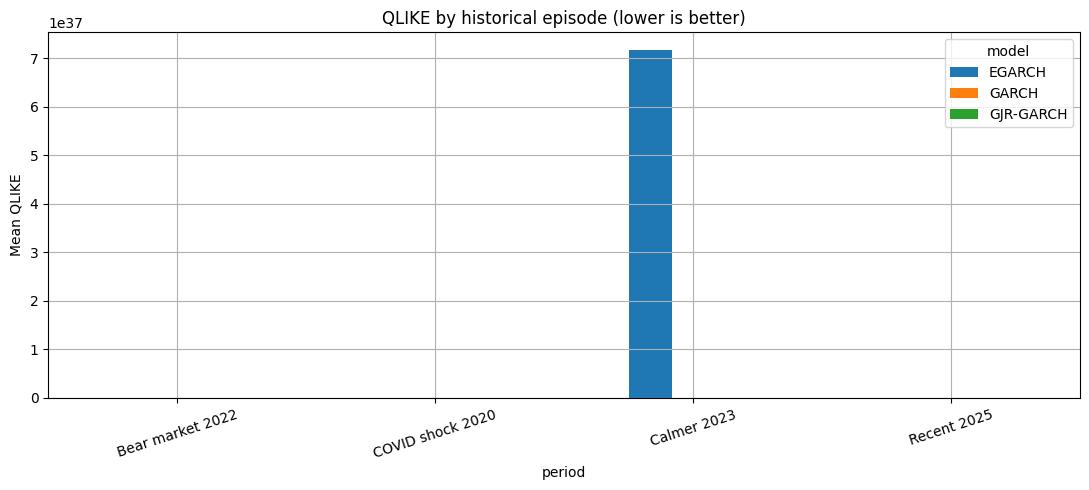

In [21]:
sensitivity=[]
for label,g in common.groupby('period',sort=False):
    for lag in [1,5,10]:
        for a,b in PAIRWISE:
            d=g[f'{a}_QLIKE_loss']-g[f'{b}_QLIKE_loss']
            mean,se,p=hac_mean_test(d,lag=lag)
            sensitivity.append({'period':label,'HAC_lag':lag,'A':a,'B':b,'mean_QLIKE_diff':mean,'p_raw':p})
sensitivity=pd.DataFrame(sensitivity)
display(sensitivity.round(4))

summary=scores[scores.period!='Pooled'].pivot(index='period',columns='model',values='QLIKE')
ax=summary.plot(kind='bar',figsize=(11,5),rot=18,title='QLIKE by historical episode (lower is better)')
ax.set_ylabel('Mean QLIKE');plt.tight_layout();plt.savefig(OUTPUT/'qlike_by_episode.png',dpi=160);plt.show()

## 9. Export reproducible evidence and use it in your paper
Exports include the actual sample, target dates, all forecasts, loss tables, fit diagnostics, missing forecasts, inference, and the configuration. Do **not** present forecast rankings as a general population result without robustness checks. This notebook is a research artifact, not investment advice.

In [22]:
pred.to_csv(OUTPUT/'all_forecasts.csv')
common.to_csv(OUTPUT/'matched_forecasts_and_losses.csv')
coverage.to_csv(OUTPUT/'forecast_coverage.csv')
scores.to_csv(OUTPUT/'period_scores.csv',index=False)
regime_scores.to_csv(OUTPUT/'ex_ante_regime_scores.csv',index=False)
regime_counts.to_csv(OUTPUT/'ex_ante_regime_counts.csv')
hac_table.to_csv(OUTPUT/'hac_pairwise_tests.csv',index=False)
bootstrap_results.to_csv(OUTPUT/'stratified_block_bootstrap.csv',index=False)
sensitivity.to_csv(OUTPUT/'hac_lag_sensitivity.csv',index=False)
fit_table.to_csv(OUTPUT/'parameter_fits.csv',index=False)
fail_table.to_csv(OUTPUT/'failed_events.csv',index=False)
config={'ticker':TICKER,'start':START,'end_exclusive':END,
        'estimation_window':ESTIMATION_WINDOW,'refit_every':REFIT_EVERY,
        'max_days_per_period':MAX_DAYS_PER_PERIOD,'periods':PERIODS,
        'seed':SEED,'versions':{'python':sys.version.split()[0], 'arch':arch.__version__,
               'yfinance':yf.__version__,'numpy':np.__version__,'pandas':pd.__version__}}
(OUTPUT/'experiment_config.json').write_text(json.dumps(config,indent=2))
import shutil
archive=shutil.make_archive('experiment04_results','zip',OUTPUT)
print('Saved',len(list(OUTPUT.iterdir())),'files to',OUTPUT,'and archive',archive)
# For Colab only, uncomment to download automatically:
# from google.colab import files
# files.download(archive)

Saved 14 files to results_exp04 and archive /content/experiment04_results.zip


## 10. Research reporting template
In your research manuscript, report: sample date range, data source and download date; estimation/refitting protocol; coverage and fit failure counts; period-specific QLIKE and MSE; ex-ante regime counts; pairwise loss differentials with corrected p-values and block-bootstrap intervals; sensitivity to HAC lags; limitations and pre-specified criteria for claims. Avoid saying “model X wins” unless its advantage is robust across evaluation choices.

**Next notebook:** `05_option_pricing_integration.ipynb` using appropriately licensed historical option quotes, with time-aligned rates, dividends, strike, maturity, bid/ask, and out-of-sample evaluation.